# 2 · A network on top of the search

Notebook 1's tile search finds one motion a tile and moves N and N+2 half of it towards each
other. Can a neural network make it more precise?

Extrapolation's answer was no: every network trained on two frames hedged, and a correction on
top of its search drifted off it from the first epoch (`../frame_gen_extra/summary.md`,
"Motion"). Interpolation is the case where learned methods usually win - both ends of the
motion are known - so it is measured again here, on the method that is already best:

1. **The network.** `models.Refine`: the search, and a small network that sees N, N+2 and the
   search's two reads and corrects them per pixel - a motion correction for each side (so N+1
   need not be half way), a blend mask (so a pixel only one frame shows can come from it), and
   pixels it draws itself, in three combinations. Its last convolution starts at zero, so
   untrained it *is* the search, and every gain is over it.
2. **The loss.** L1 and MSE, and `metrics.log_wmse`, the score itself.
3. **A rule instead.** `models.Commit`, which reads N alone where the search's two reads
   disagree.

Needs: `00_data_preprocess.ipynb`. Results: `summary.md`, "A network on top".

In [1]:
"""Settings and data."""

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import metrics, models, runs, training, webexport
from helpers.training import DATA_DIR, DEVICE

RUN_DIR = training.CHECKPOINT_DIR / "refine_runs"   # each training, resumable
HALO = 8                     # trained and scored at 8, as extrapolation's networks; also scored at 4
BATCH_SIZE = 64
MAX_EPOCHS = 300             # a safety limit; training stops once it has converged
SEED = 0
KINDS = ["page", "desktop", "photo", "screen", "video", "cursor"]

def search():
    """Notebook 1's published search."""
    return models.TileSearch(radius=4, scale=2, sharpness=10.0, stride=2, fraction=0.5, still=0.1)

manifest = training.load_manifest()
training.describe(manifest)
train_loader = training.loader(DATA_DIR, manifest, BATCH_SIZE, halo=HALO)

validation = {}
for halo in (HALO, webexport.TILE_HALO):
    inputs, targets = runs.load(DATA_DIR, "val", manifest, halo=halo)
    masks = runs.groups(manifest, "val", inputs, targets, halo)
    for kind in KINDS:
        masks[f"{kind}, changed"] = masks[kind] & masks["changed"]
    validation[halo] = (inputs, targets, masks)
inputs, targets, masks = validation[HALO]
print("val    ", inputs.shape, "->", targets.shape, f"- {masks['changed'].sum()} changed")

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N and N+2, the target N+1 between them (2x frame generation)
train  10532 runs from 681 sources
val     (3546, 2, 80, 80, 3) -> (3546, 80, 80, 3) - 1293 changed


In [2]:
"""The bar: notebook 1's methods at a halo of 8."""

BASELINES = {
    "hold N": models.Hold(),
    "mean (the mock)": models.Blend(0.5),
    "tile search": models.Interpolate(search()),
    "tile search + pick": models.TilePick(search(), window=15, sharpness=3.0),
}
results = {name: training.evaluate(model, inputs, targets, masks, HALO) for name, model in BASELINES.items()}

def table(results, group="changed"):
    base = results["tile search"][group]["wpsnr"]
    print(f"{'wPSNR, ' + group:<34}{'all':>8}{'unchgd':>8}" + "".join(f"{k:>9}" for k in KINDS) + f"{'SSIM-Y':>9}{'vs search':>11}")
    for name, r in results.items():
        print(f"{name:<34}{r[group]['wpsnr']:8.2f}{r['unchanged']['wpsnr']:8.2f}"
              + "".join(f"{r[f'{k}, changed']['wpsnr']:9.2f}" for k in KINDS)
              + f"{r[group]['ssim']:9.4f}{r[group]['wpsnr'] - base:+11.2f}")

table(results)

wPSNR, changed                         all  unchgd     page  desktop    photo   screen    video   cursor   SSIM-Y  vs search
hold N                               33.59   78.87    25.18    34.46    24.28    39.55    32.63    22.34   0.8029      -3.34
mean (the mock)                      32.91   79.68    23.86    27.44    27.02    37.73    33.42    24.58   0.8165      -4.03
tile search                          36.94   79.67    33.12    27.03    39.59    39.70    35.31    34.97   0.8761      +0.00
tile search + pick                   37.03   79.71    33.11    27.35    39.54    39.85    35.40    35.10   0.8796      +0.09


## 1 · The network

`models.Refine(search, parts)`: N, N+2 and the search's two reads (12 channels) into
`TwoScale`'s body - two stride-2 3x3 convolutions of 16 and 32 channels, three 3x3 at a
quarter of the resolution, `DepthToSpace` back up - and out at full resolution:

| parts | what it changes | parameters |
| --- | --- | --- |
| `residual` | adds pixels it draws to the search's result - a picture, as extrapolation's notebook 2 | 36,732 |
| `flow`, `mask` | moves where N and where N+2 are read, each on its own, and mixes the two reads per pixel | 38,468 |
| `flow`, `mask`, `residual` | all of it | 41,072 |

Each starts as the search. Trained at a halo of 8 with Adam - from 1e-4 where it moves reads
(offsets are in pixels: extrapolation's notebook 3 found 1e-3 too large a step), 1e-3 for the
picture alone - halving the rate when the score stalls, keeping the epoch with the best wPSNR
on the changed samples, until it converges. A sample's two frames are swapped in time half the
time: the frame between N and N+2 is the frame between N+2 and N.

**The loss** comes first, because it decided the result before anything else did. Two runs
of the motion network, under MSE and under `log_wmse`:

In [3]:
"""flow + mask under MSE and under the score itself."""

LOSSES = {"mse": lambda a, b: torch.nn.functional.mse_loss(a, b), "l1": metrics.luma_chroma_l1,
          "log_wmse": metrics.log_wmse}
RUNS = {  # name: (parts, learning rate, loss)
    "flow + mask, MSE": (("flow", "mask"), 1e-4, "mse"),
    "flow + mask, L1": (("flow", "mask"), 1e-4, "l1"),
    "flow + mask": (("flow", "mask"), 1e-4, "log_wmse"),
    "residual": (("residual",), 1e-3, "log_wmse"),
    "flow + mask + residual": (("flow", "mask", "residual"), 1e-4, "log_wmse"),
}
networks, histories, bests = {}, {}, {}

def run(name):
    parts, rate, loss = RUNS[name]
    training.seed_everything(SEED)
    networks[name] = models.Refine(search(), parts)
    histories[name], bests[name] = training.train(
        networks[name], train_loader, validation[HALO], HALO, MAX_EPOCHS, learning_rate=rate,
        loss_fn=LOSSES[loss], select=("changed", "wpsnr"), verbose=2,
        checkpoint=RUN_DIR / f"{name.replace(' ', '_').replace('+', 'and').replace(',', '')}_halo{HALO}.pt")

for name in ("flow + mask, MSE", "flow + mask, L1", "flow + mask"):
    run(name)

Training until the model stops improving, at most 300 epochs. Untrained model (repeat): val_changed_wpsnr: 36.9357.
The training is saved to /home/henrik/projects/desktop-streamer-ai/src/frame_gen_intra/checkpoints/refine_runs/flow_and_mask_MSE_halo8.pt after every epoch.
Epoch 1/300
164/164 [==============================] - 12s 74ms/step - loss: 0.0015 - val_changed_ssim_y: 0.8761 - val_changed_wpsnr: 36.2395 - val_unchanged_wpsnr: 59.3149 - learning_rate: 1.0e-04
Epoch 1: val_changed_wpsnr did not improve from 36.9357 (1 of 6 epochs without improvement)
Epoch 2/300
164/164 [==============================] - 7s 40ms/step - loss: 0.0014 - val_changed_ssim_y: 0.8761 - val_changed_wpsnr: 36.0422 - val_unchanged_wpsnr: 56.7545 - learning_rate: 1.0e-04
Epoch 2: val_changed_wpsnr did not improve from 36.9357 (2 of 6 epochs without improvement)
Epoch 3/300
164/164 [==============================] - 4s 22ms/step - loss: 0.0014 - val_changed_ssim_y: 0.8762 - val_changed_wpsnr: 36.1749 - val_u

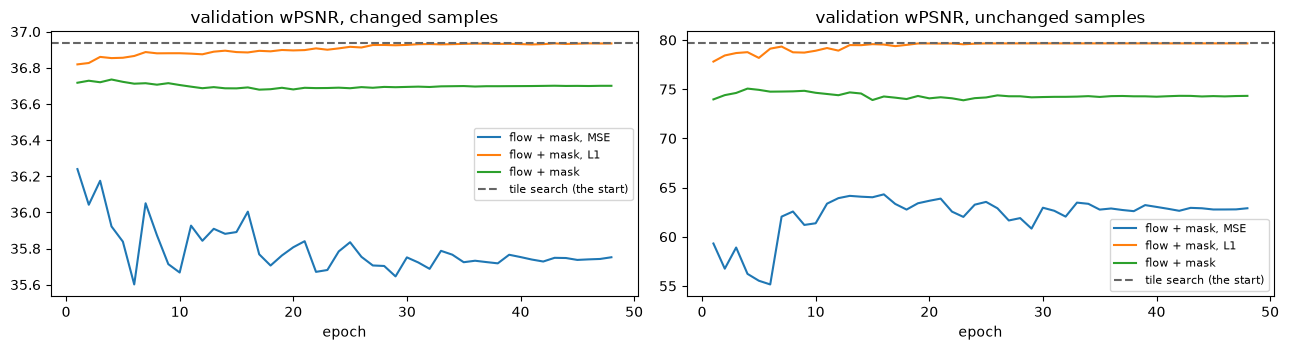

flow + mask, MSE     best epoch   0, 48 epochs; after the first: changed 36.24, unchanged 59.31 dB
flow + mask, L1      best epoch   0, 48 epochs; after the first: changed 36.82, unchanged 77.81 dB
flow + mask          best epoch   0, 48 epochs; after the first: changed 36.72, unchanged 73.97 dB


In [4]:
"""What each loss did to the score, epoch by epoch - the untrained network is the search."""

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for name in ("flow + mask, MSE", "flow + mask, L1", "flow + mask"):
    epochs = range(1, len(histories[name]) + 1)
    axes[0].plot(epochs, [h["scores"]["changed"]["wpsnr"] for h in histories[name]], label=name)
    axes[1].plot(epochs, [h["scores"]["unchanged"]["wpsnr"] for h in histories[name]], label=name)
for ax, group in zip(axes, ("changed", "unchanged")):
    ax.axhline(results["tile search"][group]["wpsnr"], color="0.4", ls="--", label="tile search (the start)")
    ax.set_title(f"validation wPSNR, {group} samples")
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for name in ("flow + mask, MSE", "flow + mask, L1", "flow + mask"):
    h = histories[name]
    print(f"{name:<20} best epoch {bests[name]['epoch']:3}, {len(h)} epochs; after the first: changed "
          f"{h[0]['scores']['changed']['wpsnr']:.2f}, unchanged {h[0]['scores']['unchanged']['wpsnr']:.2f} dB")

Under MSE the motion network loses 0.7 dB of score on the changed samples after its first epoch
(36.24 against the search's 36.94), and 20 dB on the still ones (79.67 to 59.31): the loss is a mean
over pixels, ruled by the samples with the largest errors - a menu, an uncovered desktop - where a
blur lowers it; the score is a mean of decibels per sample, ruled by the many with small errors,
where the blur costs most. L1 (77.81 on the still samples after one epoch) and `log_wmse` (73.97)
damage less - and none of the three ever beats its start: their best epoch is the untrained
search. The other two networks, under `log_wmse`:

In [5]:
for name in ("residual", "flow + mask + residual"):
    run(name)

for name in RUNS:
    results[name] = training.evaluate(networks[name], inputs, targets, masks, HALO)
table(results)

Training until the model stops improving, at most 300 epochs. Untrained model (repeat): val_changed_wpsnr: 36.9357.
The training is saved to /home/henrik/projects/desktop-streamer-ai/src/frame_gen_intra/checkpoints/refine_runs/residual_halo8.pt after every epoch.
Epoch 1/300
164/164 [==============================] - 3s 18ms/step - loss: -4.3292 - val_changed_ssim_y: 0.8761 - val_changed_wpsnr: 36.6366 - val_unchanged_wpsnr: 69.9552 - learning_rate: 1.0e-03
Epoch 1: val_changed_wpsnr did not improve from 36.9357 (1 of 6 epochs without improvement)
Epoch 2/300
164/164 [==============================] - 3s 17ms/step - loss: -4.3513 - val_changed_ssim_y: 0.8761 - val_changed_wpsnr: 36.6109 - val_unchanged_wpsnr: 68.4651 - learning_rate: 1.0e-03
Epoch 2: val_changed_wpsnr did not improve from 36.9357 (2 of 6 epochs without improvement)
Epoch 3/300
164/164 [==============================] - 3s 17ms/step - loss: -4.3567 - val_changed_ssim_y: 0.8761 - val_changed_wpsnr: 36.6567 - val_unchange

In [6]:
"""At the client's halo of 4 - the networks were trained at 8."""

x4, y4, m4 = validation[webexport.TILE_HALO]
for name, model in {**BASELINES, **{name: networks[name] for name in ("flow + mask", "flow + mask + residual")}}.items():
    r = training.evaluate(model, x4, y4, m4, webexport.TILE_HALO)["changed"]
    print(f"{name:<26}{r['wpsnr']:8.2f} dB {r['ssim']:.4f}")

hold N                       33.59 dB 0.8029
mean (the mock)              32.91 dB 0.8165
tile search                  36.72 dB 0.8763
tile search + pick           36.89 dB 0.8797
flow + mask                  36.72 dB 0.8763
flow + mask + residual       36.72 dB 0.8763


## 2 · A rule instead: commit

A change that happens in one display frame - a menu opens, a wheel notch ends, a region
redraws - is in N+1 exactly as in N or exactly as in N+2, never their mean, and N and N+2 look
the same whichever frame it happened in. A network unsure of it hedges, and the hedge is the
mean the search already draws. A rule can choose one every time instead. `models.Commit` reads N
alone where the search's two reads disagree, their mean where they agree: a change is then
drawn once, a display frame late, instead of twice at half strength. On the score that is
exactly right half the time and as wrong as holding the frame the other half - against the
mean's half wrong always - and a mean of decibels per sample rewards it. On a screen, drawn at
60 fps, it is a menu that opens 17 ms later than the host drew it, with no ghost.

In [7]:
"""Commit, against the search, by how readily it commits."""

RULES = {"N only (always commit)": models.Interpolate(search(), side="previous")}
for window in (3, 5, 9):
    for level in (2.0, 4.0, 8.0):
        RULES[f"commit, {window}x{window}, under {level:g} levels"] = models.Commit(search(), window, level)
rule_results = {"tile search": results["tile search"],
                **{name: training.evaluate(rule, inputs, targets, masks, HALO) for name, rule in RULES.items()}}
table(rule_results)

wPSNR, changed                         all  unchgd     page  desktop    photo   screen    video   cursor   SSIM-Y  vs search
tile search                          36.94   79.67    33.12    27.03    39.59    39.70    35.31    34.97   0.8761      +0.00
N only (always commit)               36.46   78.85    32.39    31.35    37.62    40.33    33.57    34.34   0.8659      -0.48
commit, 3x3, under 2 levels          36.11   79.40    31.92    29.28    38.00    39.60    33.73    34.43   0.8671      -0.83
commit, 3x3, under 4 levels          36.11   79.66    32.00    29.27    38.16    39.44    33.88    34.49   0.8680      -0.82
commit, 3x3, under 8 levels          36.20   79.74    32.04    29.30    38.34    39.38    34.19    34.47   0.8698      -0.73
commit, 5x5, under 2 levels          36.16   79.46    31.96    29.47    38.05    39.66    33.75    34.45   0.8673      -0.78
commit, 5x5, under 4 levels          36.19   79.68    32.03    29.48    38.25    39.54    33.94    34.53   0.8685      -0.75


## What it says

- **A network does not make the search more precise.** Trained to convergence - under MSE, L1 or
  the score itself - none of the five beats its own start: in every run the best epoch is the
  untrained search (36.94 dB on the changed samples). Under MSE the motion network loses 0.7 dB
  on the changed samples and 20 on the still ones after one epoch.
- **A change in one frame is what it cannot draw.** A menu that opens or a wheel notch that ends
  is in N+1 exactly as in N or exactly as in N+2, and N and N+2 look the same whichever it was:
  unsure, a network hedges, and the hedge is the mean the search already draws there.
- **Committing to N loses on this set**: −0.5 to −0.8 dB over all changed samples (N alone,
  always: −0.48). It gains on the drawn desktops (+4.3 dB for N alone, 27.03 → 31.35) and a little
  on the screens (+0.6), and loses on pages, photos and video. On the first set - whose drawn
  scenes put every stop on a received frame - it was +0.7. Not exported; notebook 4 lets a
  decision per tile choose a frame alone where that pays.